# LSC Landmark Dataset — Loading & Visualization

Loads the Colombian Sign Language (LSC) landmark dataset via `signai_landmarks.load_dataset`
and visualizes class balance, sequence-length distribution, and the MediaPipe Holistic
skeleton (pose + both hands) extracted from the landmark vectors.

In [1]:
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np

from signai_landmarks import load_dataset
from signai_landmarks.keypoints import HAND_CONNECTIONS, POSE_CONNECTIONS, split_frame

%matplotlib inline

## Load the dataset

In [2]:
SIGN_NAMES = {
    1: "Café",
    2: "Aromática",
    3: "Hola",
    4: "¿Qué necesitas?",
    5: "Con gusto",
}

X, y = load_dataset("../data/landmarks")
print(f"{len(X)} clips loaded")
print(f"first clip shape: {X[0].shape} (frames, features)")
print(f"classes present: {sorted(int(c) for c in set(y))}")

1500 clips loaded
first clip shape: (47, 1662) (frames, features)
classes present: [1, 2, 3, 4, 5]


## Class distribution

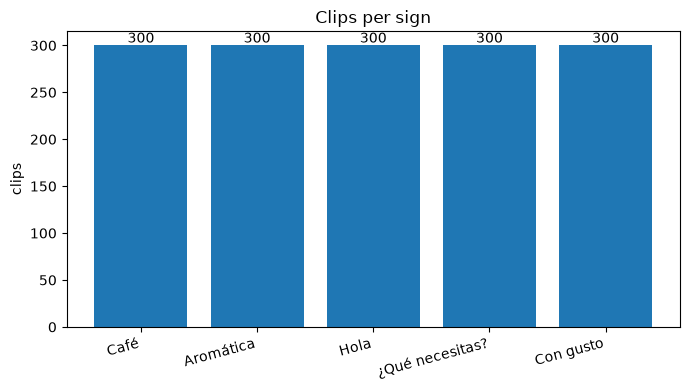

In [3]:
counts = Counter(y)
labels = [SIGN_NAMES[c] for c in sorted(counts)]
values = [counts[c] for c in sorted(counts)]

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(labels, values, color="tab:blue")
ax.set_ylabel("clips")
ax.set_title("Clips per sign")
for i, v in enumerate(values):
    ax.text(i, v + 3, str(v), ha="center")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

## Sequence-length (frame count) distribution

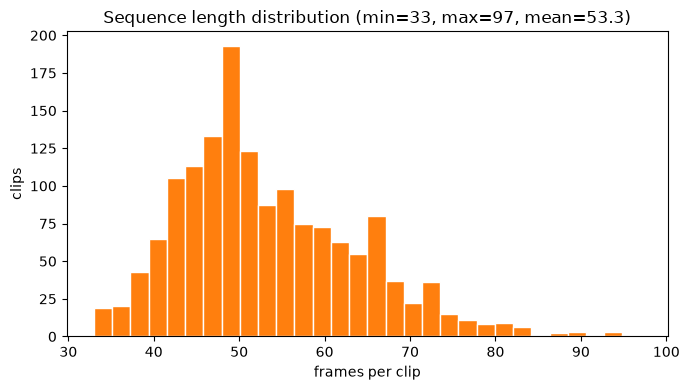

In [4]:
lengths = np.array([seq.shape[0] for seq in X])

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(lengths, bins=30, color="tab:orange", edgecolor="white")
ax.set_xlabel("frames per clip")
ax.set_ylabel("clips")
ax.set_title(
    f"Sequence length distribution "
    f"(min={lengths.min()}, max={lengths.max()}, mean={lengths.mean():.1f})"
)
plt.tight_layout()
plt.show()

## Skeleton preview — one example per sign

Each frame is split into its MediaPipe Holistic parts (pose, face, left/right hand);
here we draw the pose and hand skeletons for the middle frame of the first clip of
every sign. Landmark `x`/`y` are normalized image coordinates, so the y-axis is
inverted to match a natural upright view.

In [5]:
def plot_skeleton(ax, frame, title=None):
    parts = split_frame(frame)

    def draw(points, connections, color):
        for a, b in connections:
            ax.plot(
                [points[a, 0], points[b, 0]],
                [points[a, 1], points[b, 1]],
                color=color, linewidth=1,
            )
        ax.scatter(points[:, 0], points[:, 1], s=8, color=color)

    draw(parts["pose"], POSE_CONNECTIONS, "tab:blue")
    draw(parts["left_hand"], HAND_CONNECTIONS, "tab:green")
    draw(parts["right_hand"], HAND_CONNECTIONS, "tab:red")

    ax.set_xlim(0, 1)
    ax.set_ylim(1, 0)
    ax.set_aspect("equal")
    ax.axis("off")
    if title:
        ax.set_title(title)

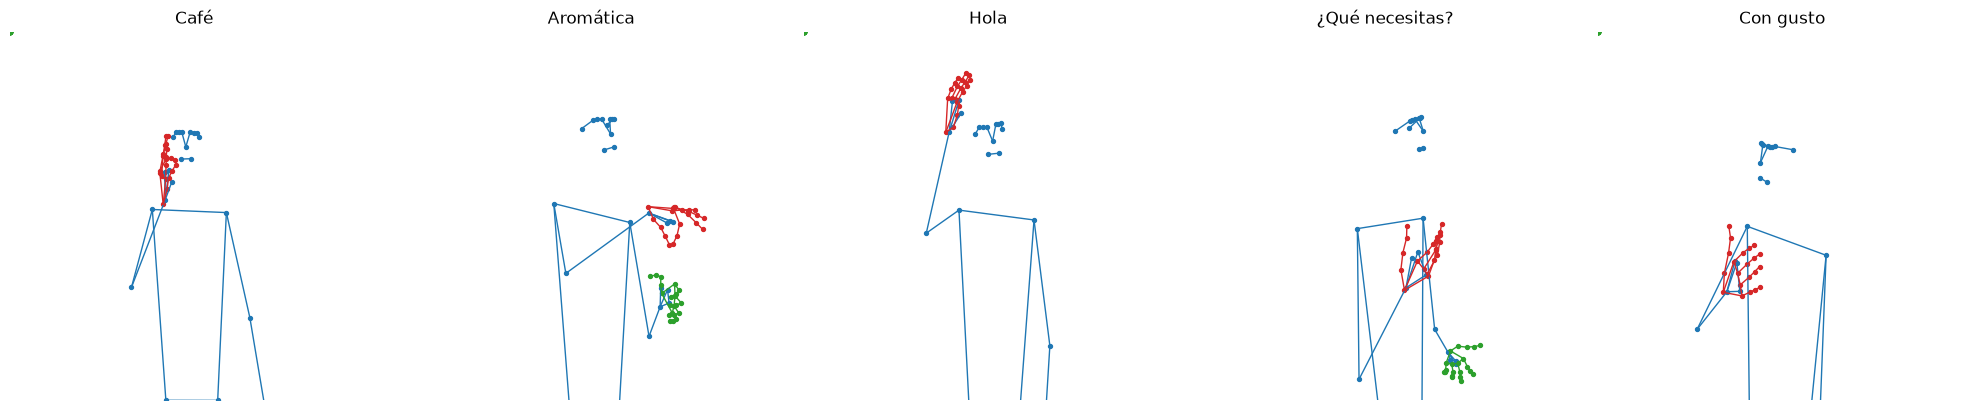

In [8]:
first_clip_idx_per_class = {c: int(np.where(y == c)[0][0]) for c in sorted(set(y))}

fig, axes = plt.subplots(
    1, len(first_clip_idx_per_class), figsize=(4 * len(first_clip_idx_per_class), 4)
)
for ax, (class_label, idx) in zip(axes, first_clip_idx_per_class.items()):
    clip = X[idx]
    middle_frame = clip[clip.shape[0] // 2]
    plot_skeleton(ax, middle_frame, title=SIGN_NAMES[class_label])
plt.tight_layout()
plt.show()

## Motion within a clip

Small multiples of evenly spaced frames from a single clip, showing how the pose and
hands move over the course of one sign performance.

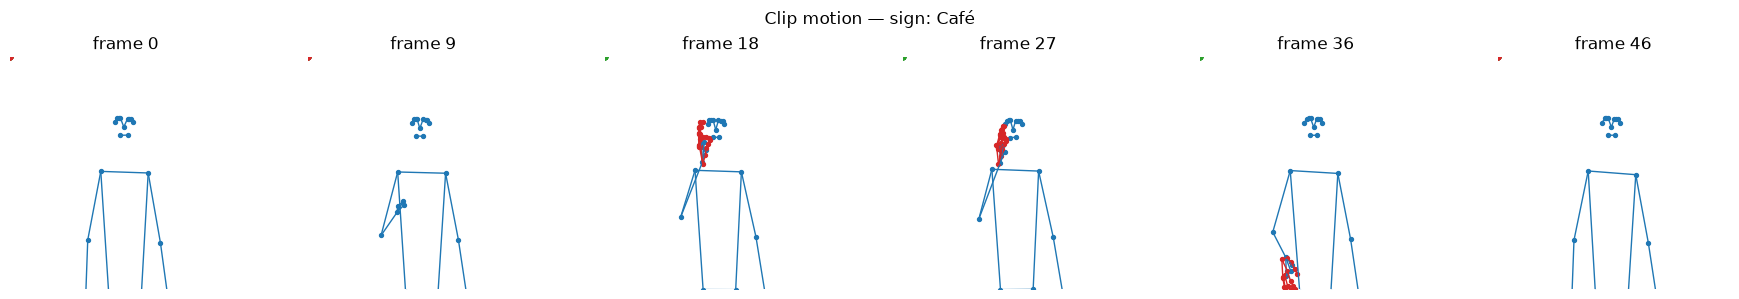

In [9]:
sample_idx = first_clip_idx_per_class[1]
clip = X[sample_idx]
n_frames_to_show = min(6, clip.shape[0])
frame_indices = np.linspace(0, clip.shape[0] - 1, n_frames_to_show, dtype=int)

fig, axes = plt.subplots(1, n_frames_to_show, figsize=(3 * n_frames_to_show, 3))
for ax, frame_idx in zip(axes, frame_indices):
    plot_skeleton(ax, clip[frame_idx], title=f"frame {frame_idx}")
fig.suptitle(f"Clip motion — sign: {SIGN_NAMES[1]}")
plt.tight_layout()
plt.show()